# DBSCAN from Scratch

DBSCAN is a clustering algorithm that is fairly straightforward in how it works, yet very stable and robust at identifying clusters and, above all, outliers, compared with e.g. classic K-Means. It is density-based: it groups data points (in any number of dimensions) according to whether they lie close together. This lets it identify outliers, i.e. noise.

This notebook implements DBSCAN from scratch and benchmarks it against the scikit-learn implementation on the standardized Iris dataset (bundled with scikit-learn).

### Key concepts and parameters
- **Parameters:**
  - `ε (epsilon)` – neighborhood radius (distance from a point).
  - `minPts` – minimum number of points in the ε-neighborhood.

- **ε-neighborhood of a point:**

$$
N_\varepsilon(x) = \{ y \mid d(x,y) \leq \varepsilon \}
$$

- **Point types:**
  - **Core point:** has at least `minPts` neighbors.
  - **Border point:** is not a core point, but lies in the neighborhood of a core point.
  - **Noise point:** is neither a core nor a border point.

- **Density reachability:**
  Point `y` is density-reachable from `x` if there is a chain of core points in which each point lies in the ε-neighborhood of the previous one.

- **Density connectivity:**
  Two points are density-connected if there is a point `o` from which both are density-reachable.

- **Cluster:**
  A maximal set of mutually density-connected points.


## Algorithm step by step

A good video explaining the algorithm and its steps: [DBSCAN](https://youtu.be/RDZUdRSDOok)

1. Mark all points as **unvisited**.
2. For each point:
   - Find its ε-neighborhood.
   - If the number of neighbors < minPts → mark it as **noise**.
   - If it is a core point → create a new cluster and **expand** it:
     - Add its neighbors.
     - If a neighbor is a core point, recursively expand its neighborhood too.
3. Border points join a cluster during expansion.
4. Noise points remain outside all clusters.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from collections import deque
import time

In [2]:
iris = load_iris()
X = iris.data
y = iris.target
X_scaled = StandardScaler().fit_transform(X)

Before implementing and comparing DBSCAN, we need to find a suitable epsilon distance and number of neighbors for the dataset.

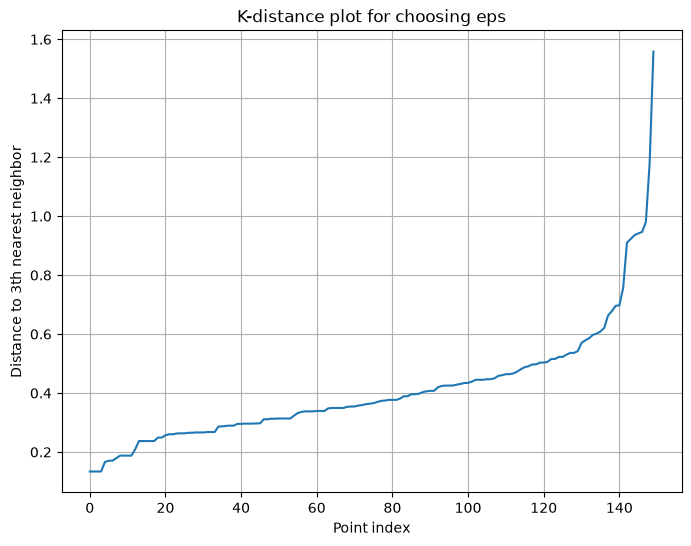

In [3]:
minPts = 3
neighbors = NearestNeighbors(n_neighbors=minPts)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8,6))
plt.plot(k_distances)
plt.xlabel("Point index")
plt.ylabel(f"Distance to {minPts}th nearest neighbor")
plt.title("K-distance plot for choosing eps")
plt.grid(True)
plt.show()

In [4]:
eps = 0.9

## Custom DBSCAN implementation

My first version (not included here) was naive, with $O(n^2)$ complexity. This version is faster: it uses `NearestNeighbors` radius queries, which reduces the time complexity to $O(n \log n)$.

In [5]:
# Labels for points that have not been visited yet, and for noise (outliers)
UNVISITED = -2
NOISE = -1

class DBSCANFast:
    # eps - neighborhood radius (epsilon, see above)
    # min_samples - minimum number of neighbors for a point to be a CORE point
    # algorithm - passed to NearestNeighbors
    # leaf_size - passed to NearestNeighbors
    def __init__(self, eps=0.5, min_samples=5, algorithm='auto', leaf_size=30):
        self.eps = eps
        self.min_samples = min_samples
        self.algorithm = algorithm
        self.leaf_size = leaf_size
        self.labels_ = None

    # Main pass of the algorithm
    def fit(self, X):
        n = X.shape[0]
        # All points start as unvisited
        self.labels_ = np.full(n, UNVISITED, dtype=int)
        # Build the structure used to find all points within radius epsilon
        nbrs = NearestNeighbors(radius=self.eps, algorithm=self.algorithm, leaf_size=self.leaf_size)
        nbrs.fit(X)
        # Neighbors (including the point itself) in the ε-neighborhood of each point
        all_neighbors = nbrs.radius_neighbors(X, return_distance=False)
        cluster_id = 0

        # Main loop: classify CORE vs NOISE, then start the expansion
        for i in range(n):
            # Skip points that have already been visited
            if self.labels_[i] != UNVISITED:
                continue

            neighbors = all_neighbors[i]
            # Fewer than min_samples neighbors = NOISE, otherwise it is a CORE point
            if neighbors.size < self.min_samples:
                self.labels_[i] = NOISE
            else:
                # For a CORE point, traverse the whole cluster and collect all its points
                self._expand_cluster(i, neighbors.tolist(), cluster_id, all_neighbors)
                # Move on to the next cluster
                cluster_id += 1

        return self

    # BFS (breadth-first search) using a deque as a queue
    def _expand_cluster(self, i, neighbors, cluster_id, all_neighbors):
        # deque: append on the right, pop from the left (FIFO queue)
        queue = deque(neighbors)
        self.labels_[i] = cluster_id
        while queue:
            j = queue.popleft()

            # NOISE points are assigned to the cluster as BORDER points
            if self.labels_[j] == NOISE:
                self.labels_[j] = cluster_id
            # Skip already processed points and points just relabelled from NOISE to BORDER
            if self.labels_[j] != UNVISITED:
                continue

            # Assign the point to the current cluster
            self.labels_[j] = cluster_id

            # If it has enough neighbors, it is a CORE point: expand the cluster
            ns = all_neighbors[j]
            if ns.size >= self.min_samples:
                for idx in ns:
                    if self.labels_[idx] == UNVISITED:
                        queue.append(idx)


## Comparison with scikit-learn

In [6]:
times_custom = []
for _ in range(100):
    start = time.perf_counter()
    labels_custom = DBSCANFast(eps, minPts).fit(X_scaled).labels_
    times_custom.append(time.perf_counter() - start)
avg_time_custom = np.mean(times_custom)

times_lib = []
for _ in range(100):
    start = time.perf_counter()
    labels_lib = DBSCAN(eps=eps, min_samples=minPts).fit(X_scaled).labels_
    times_lib.append(time.perf_counter() - start)
avg_time_lib = np.mean(times_lib)

Custom DBSCAN implementation:
  Number of clusters: 2
  Number of noise points: 4
  Silhouette Coefficient:0.52
  Average runtime over 100 runs: 0.002304 s

Library DBSCAN (sklearn):
  Number of clusters: 2
  Number of noise points: 4
  Silhouette Coefficient:0.52
  Average runtime over 100 runs: 0.001593 s



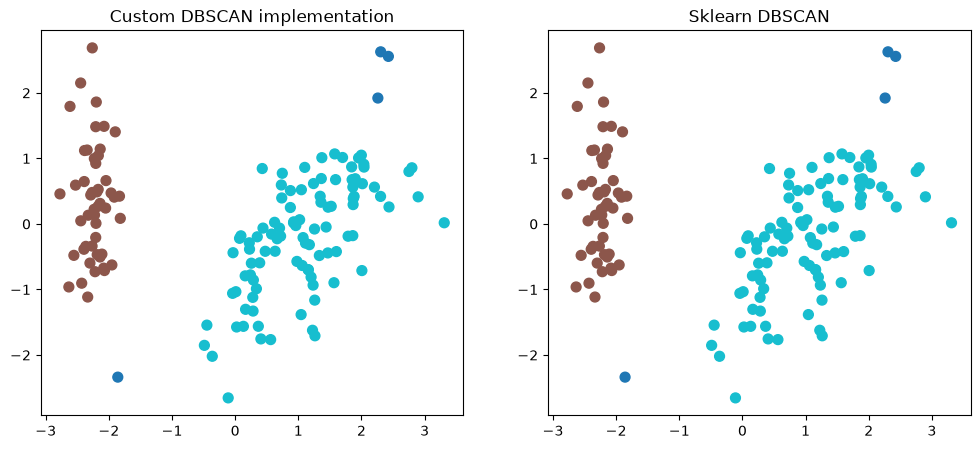

In [7]:
def summarize(labels, name, runtime):
    clusters = set(labels) - {-1}
    noise_count = np.sum(labels == -1)
    sc = silhouette_score(X_scaled, labels)
    print(f"{name}:")
    print(f"  Number of clusters: {len(clusters)}")
    print(f"  Number of noise points: {noise_count}")
    print(f"  Silhouette Coefficient:%0.2f" % sc)
    print(f"  Average runtime over 100 runs: {runtime:.6f} s")
    print()

summarize(labels_custom, "Custom DBSCAN implementation", avg_time_custom)
summarize(labels_lib, "Library DBSCAN (sklearn)", avg_time_lib)


pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Custom DBSCAN
axes[0].scatter(X_pca[:,0], X_pca[:,1], c=labels_custom, cmap="tab10", s=50)
axes[0].set_title("Custom DBSCAN implementation")

# Library DBSCAN
axes[1].scatter(X_pca[:,0], X_pca[:,1], c=labels_lib, cmap="tab10", s=50)
axes[1].set_title("Sklearn DBSCAN")

plt.show()